In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import interpolate
from scipy.stats import gaussian_kde
import glob
import pickle
import matplotlib
import os
from numpy import correlate

matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

In [2]:
Fs = 3e4
out_path = './6_NaturalBehavior/Clipped_test/'

In [7]:
all_files = glob.glob('./dataFolder/6_NaturalBehavior/Clipped_test/*_Prediction.pickle')

In [9]:
for filepath in all_files[0:1]:
    with open(filepath, 'rb') as f:
        savedData = pickle.load(f)
    
    p_spike   = savedData[4]
    upsampled = savedData[6]
    
    moth     = os.path.basename(filepath).split('_')[0]
    unitID   = os.path.basename(filepath).split('_')[1]
    vid_moth = os.path.basename(filepath).split('_')[3]
    
    valid    = ~np.isnan(p_spike)
    predcorr = np.correlate(p_spike[valid] - np.mean(p_spike[valid]),
                        upsampled[valid] - np.mean(upsampled[valid]), mode='full')
    predcorr_normalised = predcorr / (len(p_spike[valid]) * np.std(p_spike[valid]) * np.std(upsampled[valid]))
    lags     = np.arange(-(valid.sum()-1), valid.sum()) / Fs
    peak_idx = np.argmax(np.abs(predcorr_normalised))

    # plt.figure(figsize=(10, 3))
    # plt.plot(lags, predcorr_normalised, 'k', linewidth=0.8)
    # plt.xlabel('Lag (s)')
    # plt.ylabel('Correlation')
    # plt.title(f'{moth} {unitID} {vid_moth}')
    # plt.show()

    print(f'{moth} {unitID} {vid_moth}: peak = {predcorr_normalised[peak_idx]:.4f} at lag = {lags[peak_idx]:.4f}s')

#     predcorr_df = pd.DataFrame({'lag_seconds': lags, 'predcorr_normalised': predcorr_normalised})
#     predcorr_df.to_csv(out_path + moth + '_' + unitID + '_for_' + vid_moth + '_predcorrnorm.csv', index=False)

m23 unit1 MVm11: peak = 0.8784 at lag = 0.0005s


In [15]:
valid

array([False, False, False, ...,  True,  True,  True], shape=(299700,))

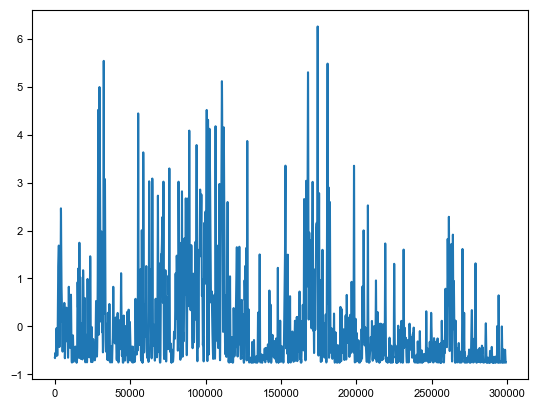

In [30]:
# plt.plot(p_spike)
a_norm = (p_spike[valid] - np.mean(p_spike[valid])) / np.std(p_spike[valid])
plt.plot(a_norm)

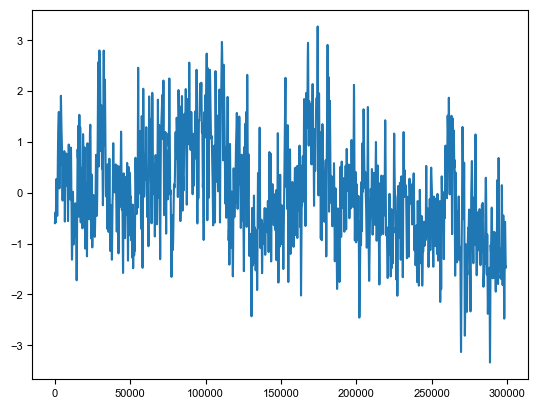

In [29]:
b_norm = (upsampled[valid] - np.mean(upsampled[valid]))/ np.std(upsampled[valid])
plt.plot(b_norm)

In [33]:
crosscor = np.correlate(a_norm, b_norm, mode = 'full')
test_crosscor = np.correlate(p_spike[valid], upsampled[valid], mode = 'full')

In [22]:
test = np.correlate(upsampled[valid], upsampled[valid], mode= 'full')

In [25]:
test_norm = test/ (len(upsampled[valid]) * np.std(upsampled[valid]) * np.std(upsampled[valid]))

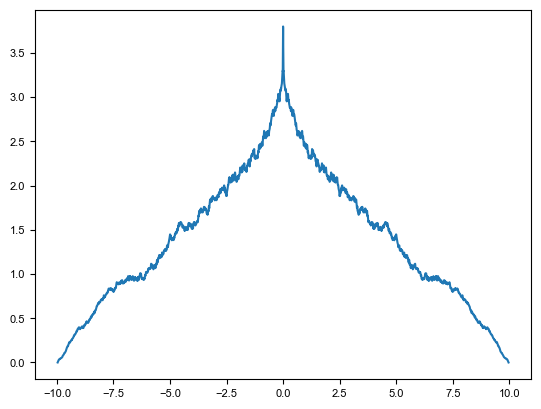

In [26]:
plt.plot(lags, test_norm)

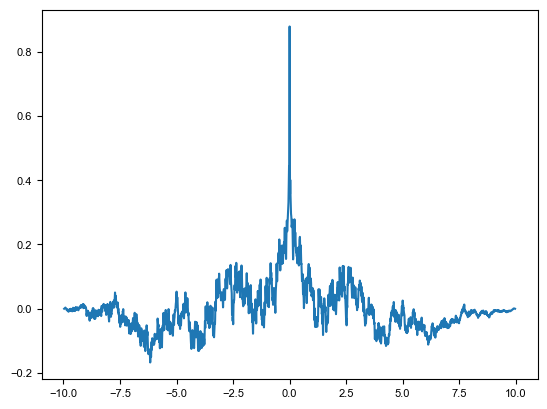

In [10]:
plt.plot(lags, predcorr_normalised)

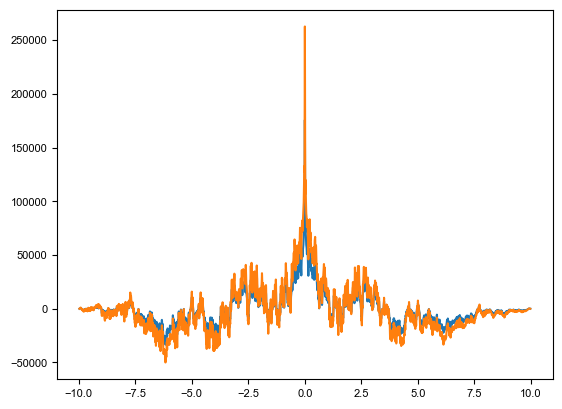

In [35]:
plt.plot(lags, predcorr)
plt.plot(lags, crosscor)
# plt.plot(lags, test_crosscor)